# Extended Data Fig. 2: d2 robustness and the other measures by state

Extended Data Fig. 1 b–g of the first submission on non-overlapping windows, except c (state transitions) and the firing-rate range in f, which use all windows. d2 = d2 (2024 Euclidean, AR p = 20, 40 ms).

- **a** AR(20) variance explained by window length (NREM), 0.5–60 s, each length on windows non-overlapping at that length (`ed_nonoverlap_ed1b.py`).
- **b** SNR of d2 (|d2| / its uncertainty), 30 s vs 60 s windows, by state; session-paired Wilcoxon within and between window lengths.
- **c** d2 (z per session) around NREM→Awake / REM / NREM transitions, all windows.
- **d** d2, wake vs sleep, every wake window; paired comparison of session medians.
- **e** branching ratio by state, 10 s windows non-overlapping at 10 s, every wake window.
- **f** left: d2 (raw) vs MUA (z within session × wake/sleep), every wake window; legend r = per-session Pearson r pooled by random-effects meta-analysis of Fisher z (sessions with ≥ 4 windows, `meta_r`). Right: spontaneous firing-rate range by d2 bin (per session and d2 bin, 10 log10(p95 / p05) of the 30 s windows' MUA over its bin mean, min–max scaled within each state), all windows, Stouffer's combined z.
- **g** fraction of non-overlapping 30 s windows whose AR(p) residuals are white (Ljung–Box, 50 lags, df = 50 − p, p > 0.05), by AR order and state, 18 sessions (`ljungbox_df_audit.py`).
- **h** d2 by state, full window and ripple-excised: per-session medians, mean ± SEM, 16 sessions (14 with REM), wake split by the window centre; NREM vs REM and Wake non-θ vs Wake θ, session-paired Wilcoxon (`d2_arms_raw.py`).
- a–e are drawn by the first-submission notebooks, run as `ed_nonoverlap.py` runs them (`F.run_rv1_capture`).

In [1]:
# Data: ../csv/FigS2_AF_robustness/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'FigS2_AF_robustness'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import numpy as np
import matplotlib.pyplot as plt
import final_figs as F                     # print styles, saving, stars

## a–e: the first-submission ED1 b–f notebooks on non-overlapping windows (c on all windows)

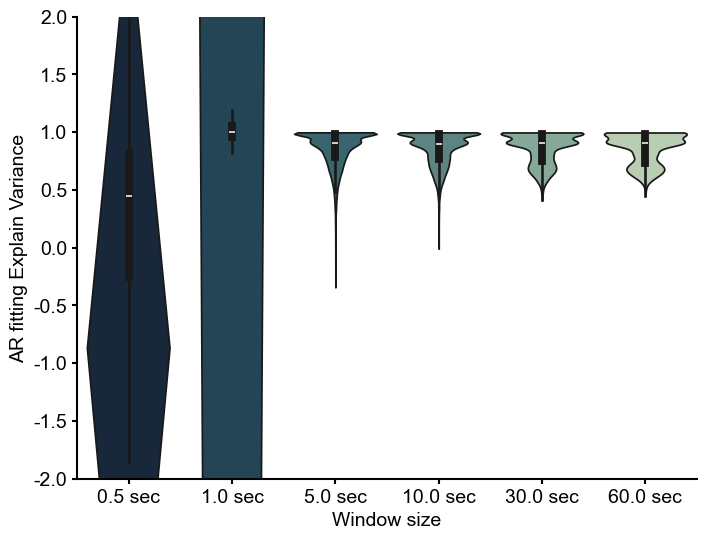

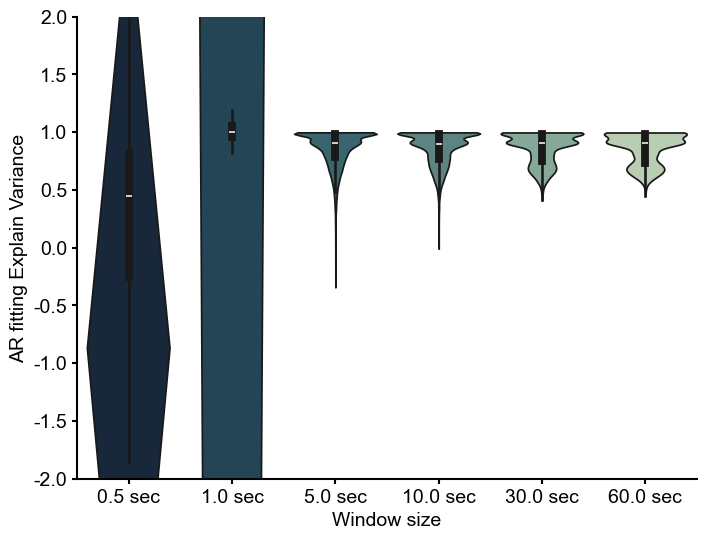

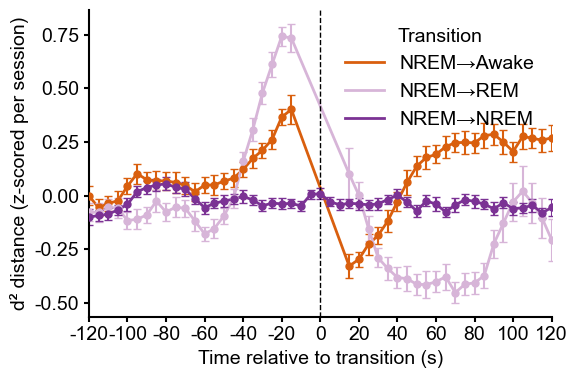

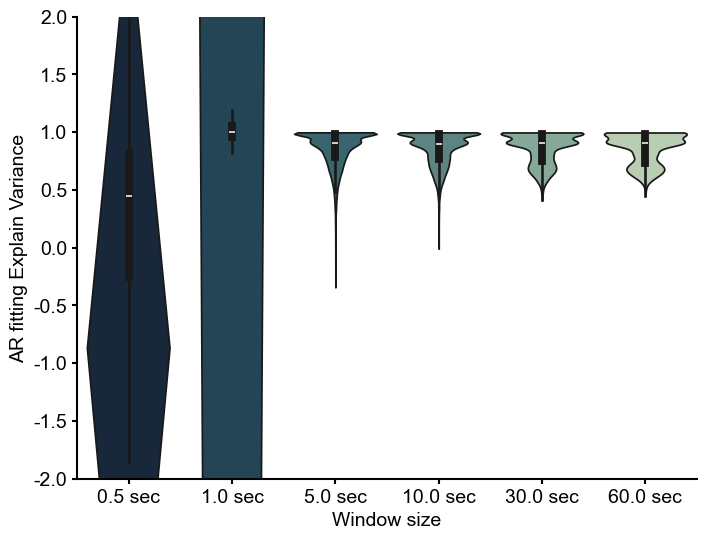

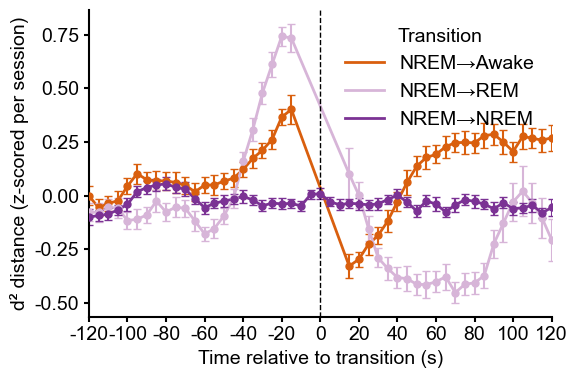

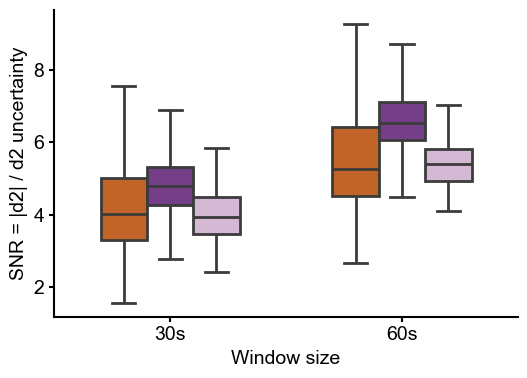

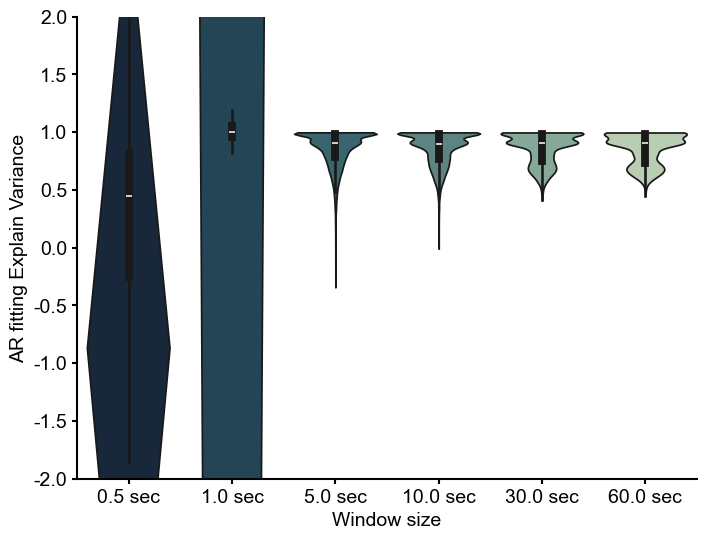

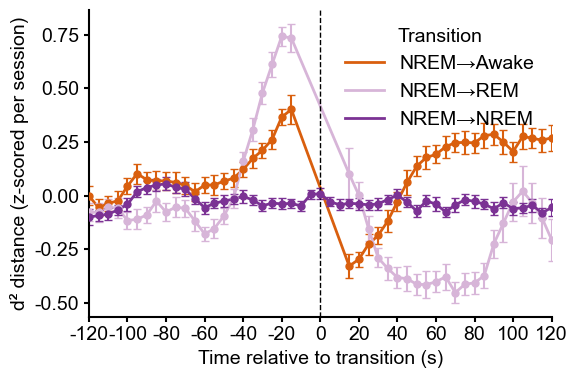

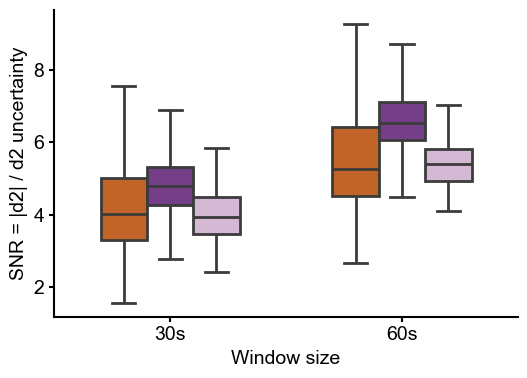

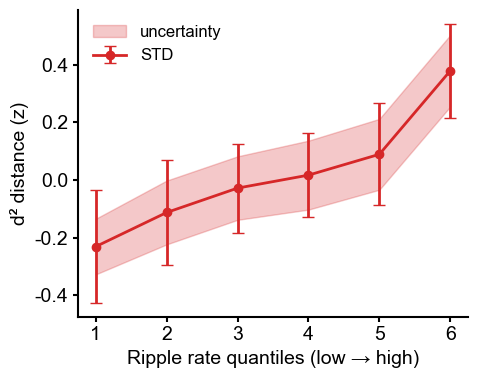

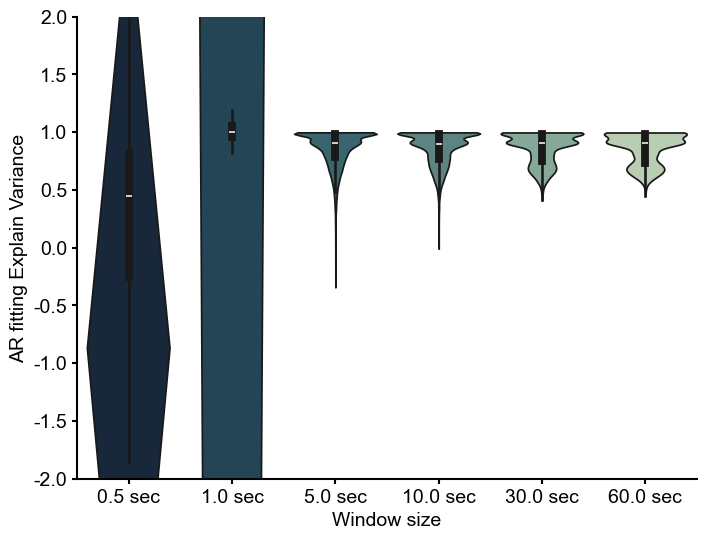

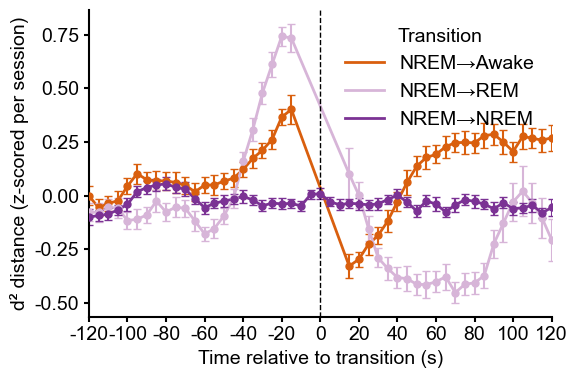

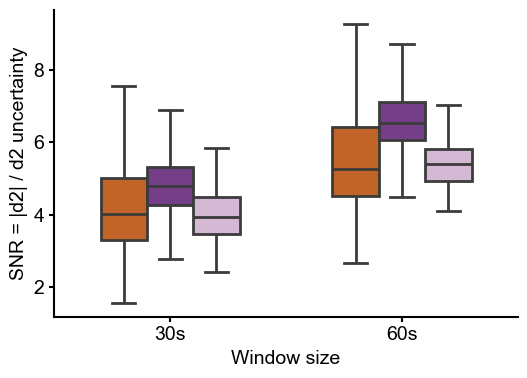

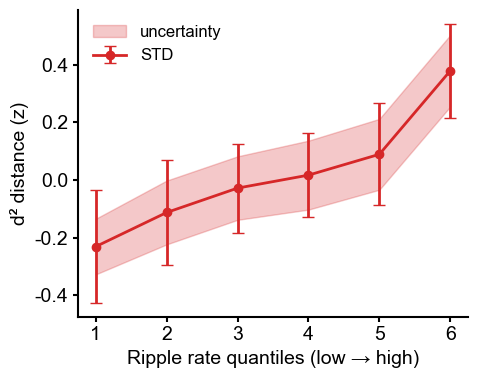

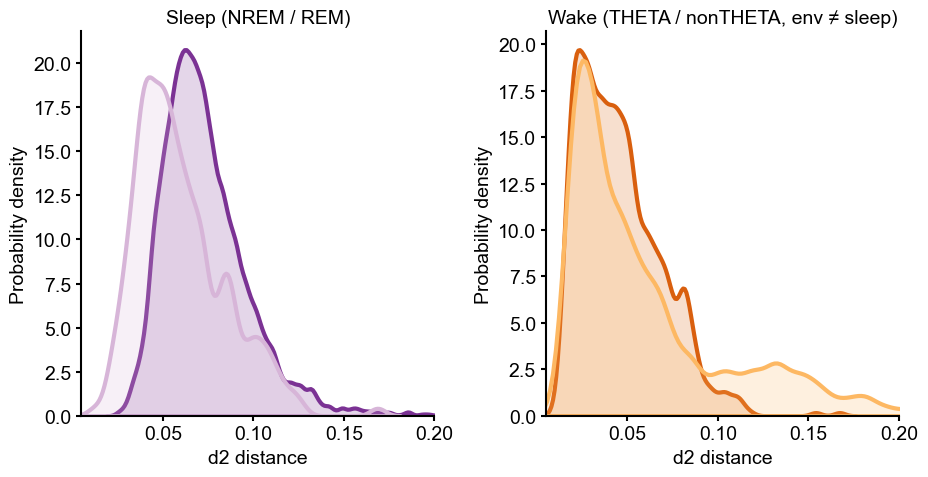

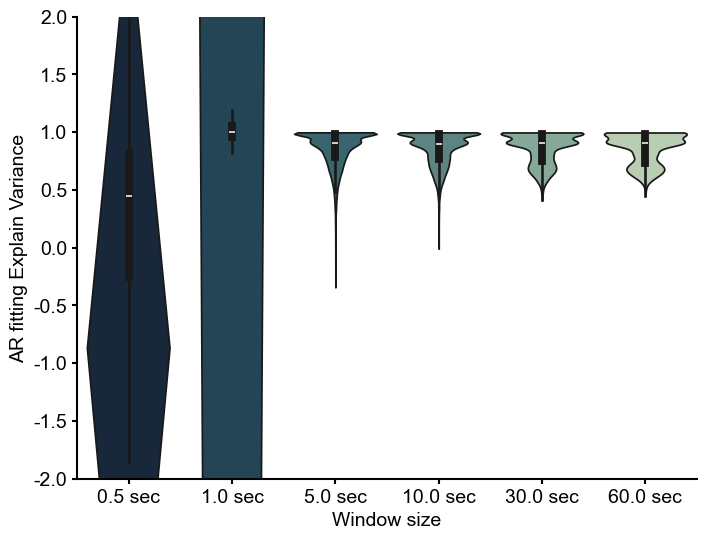

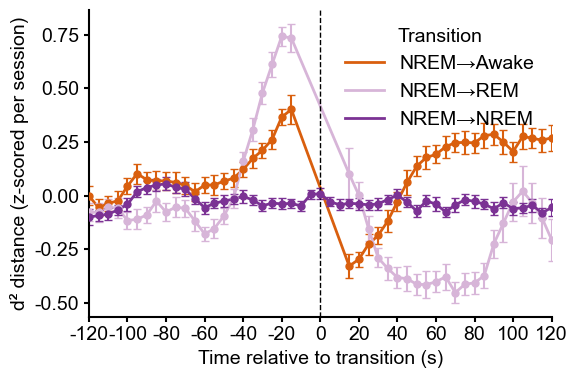

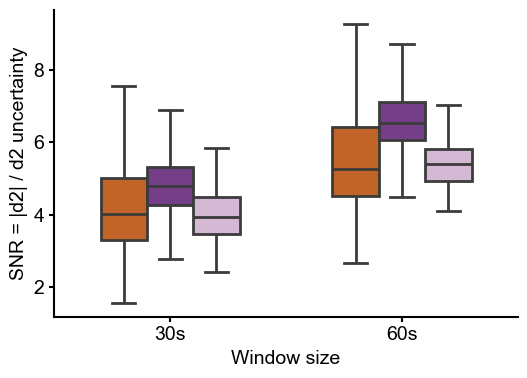

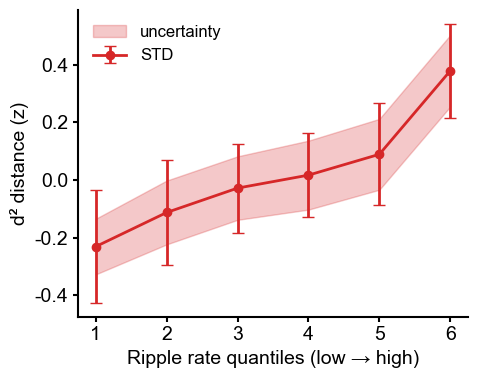

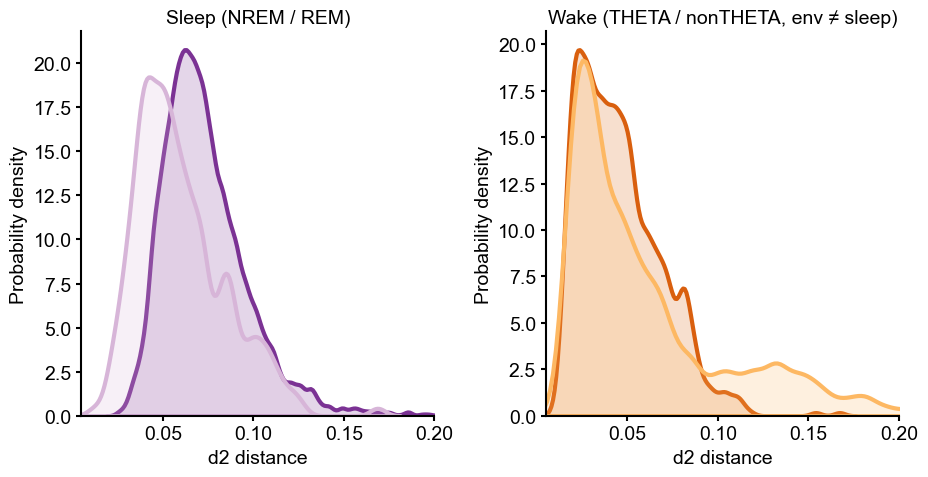

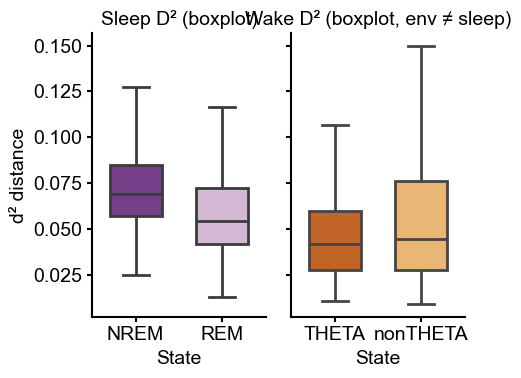

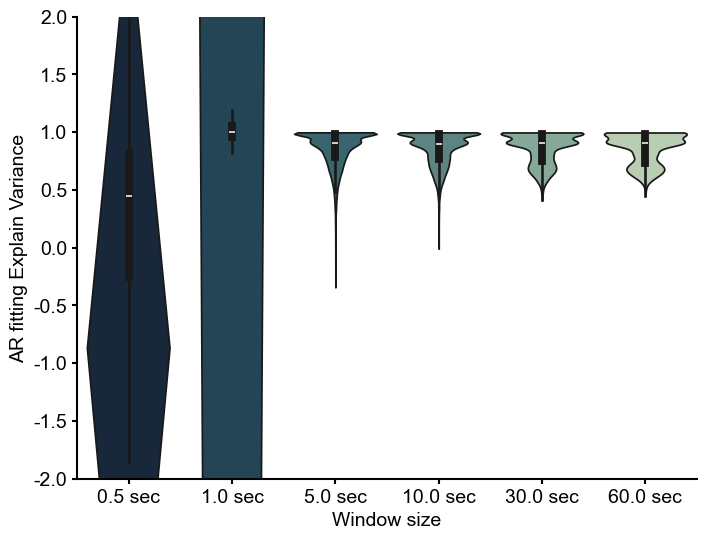

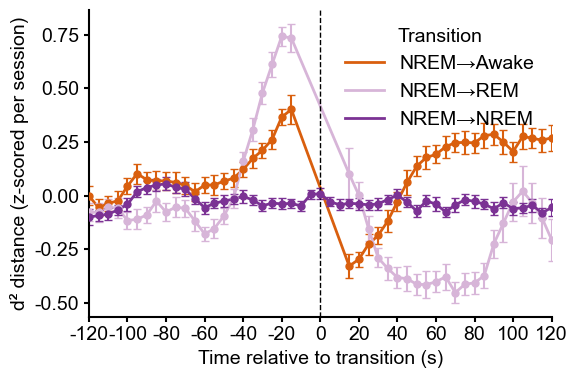

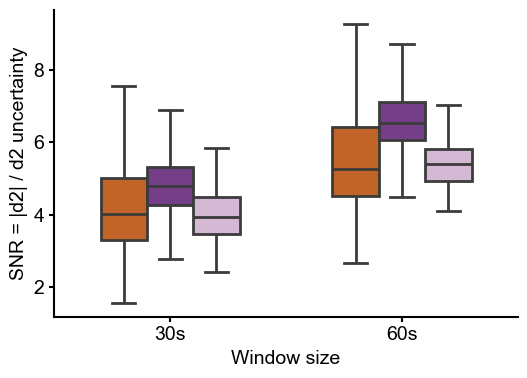

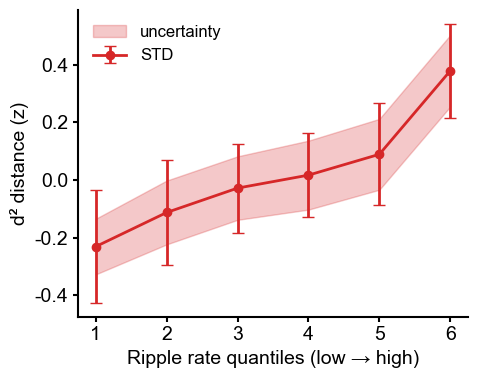

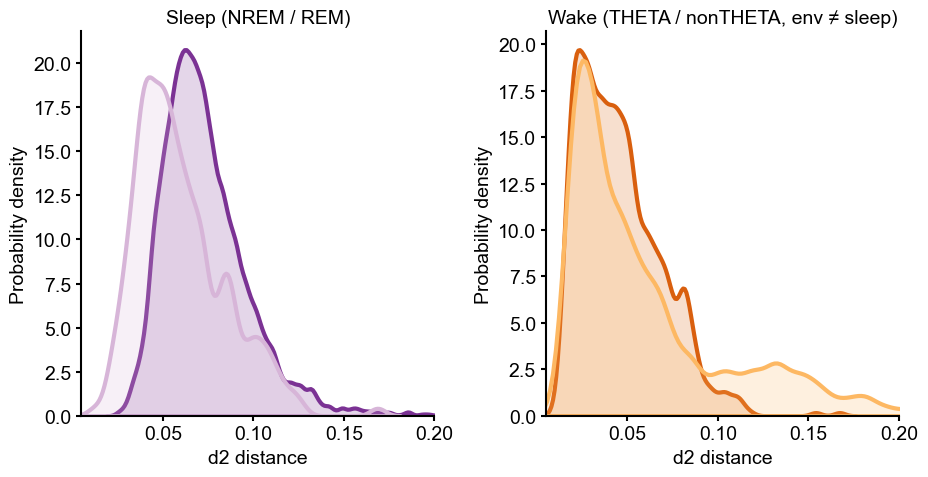

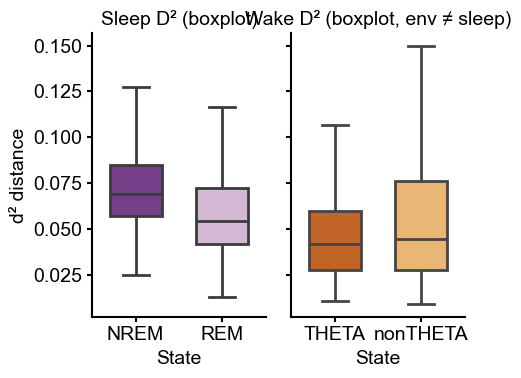

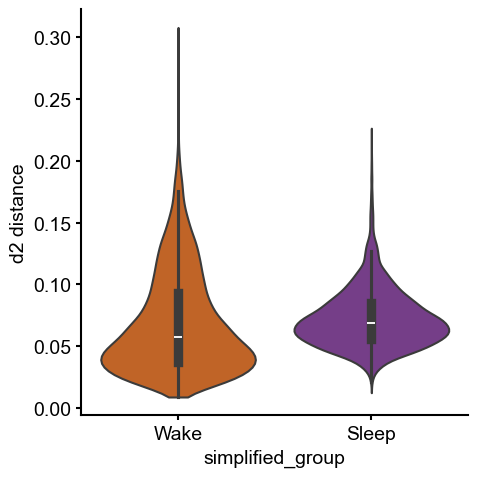

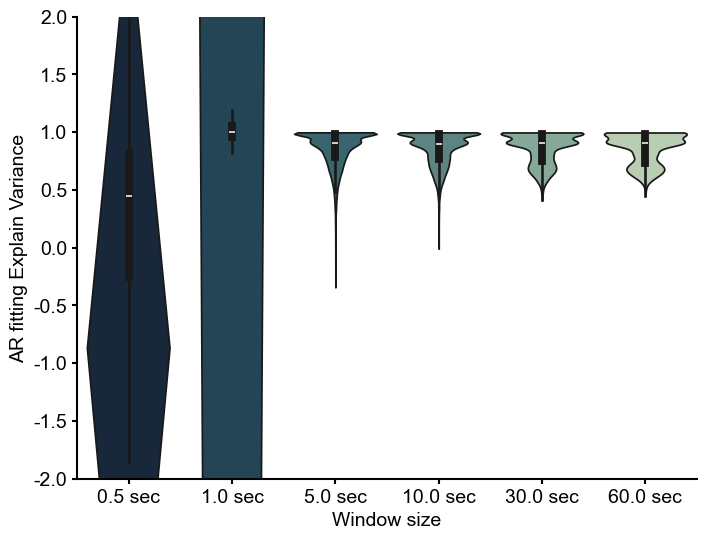

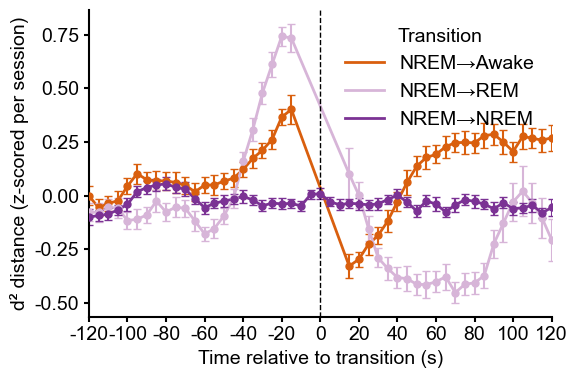

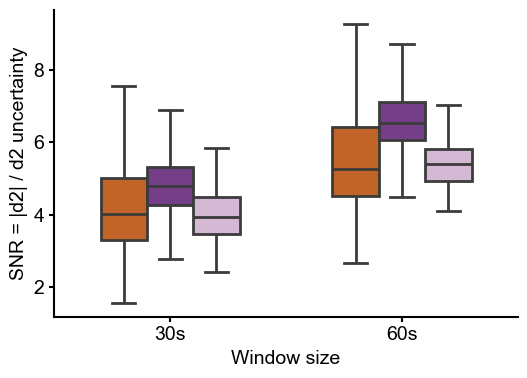

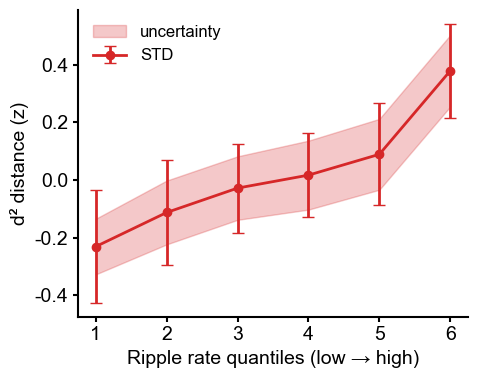

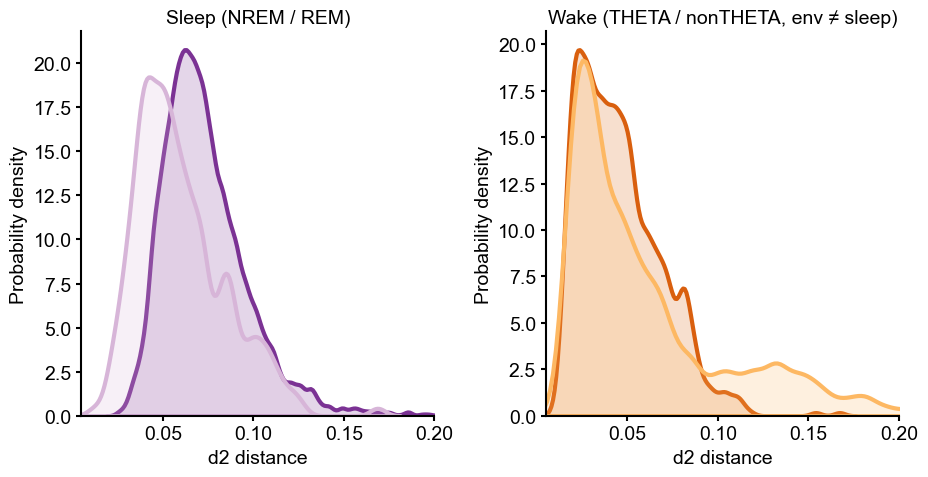

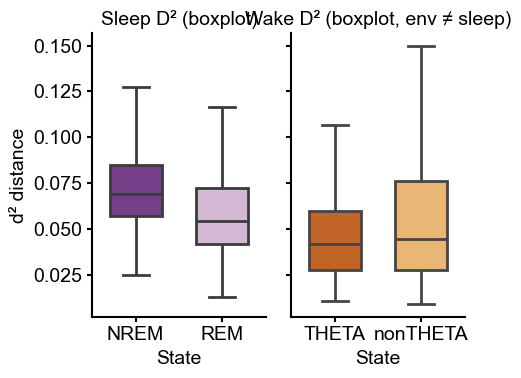

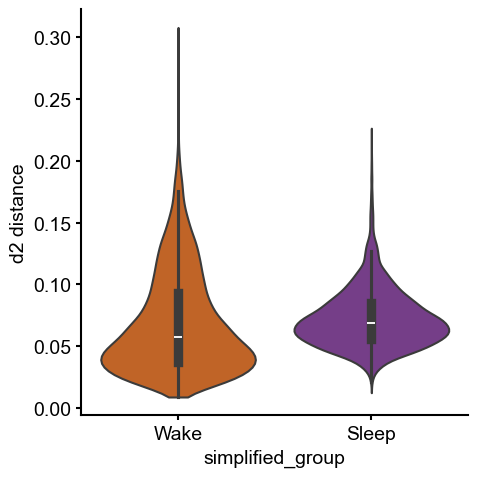

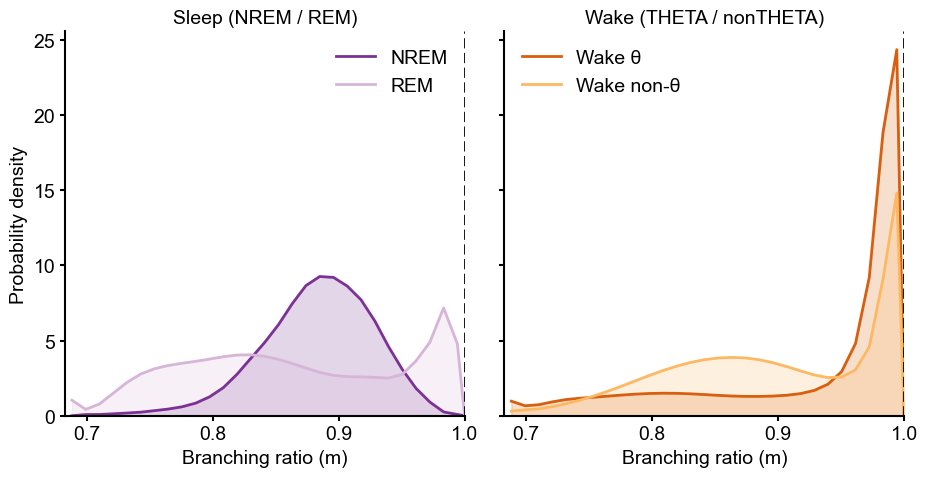

saved figure_output\supplementary\FigS2\FigS2_A_explained_variance.svg / .png


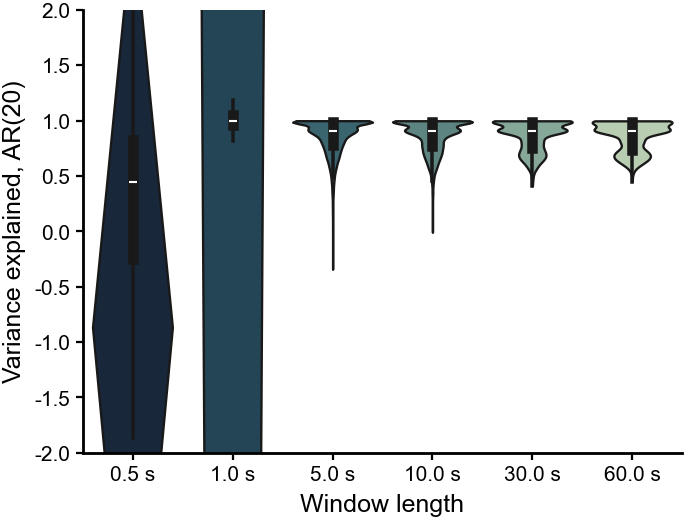

b: two-sided paired Wilcoxon signed-rank, Holm-corrected: NREM vs Wake p = 0.000153 (30 s), 0.00293 (60 s); NREM vs REM p = 0.000153 (30 s), 0.00391 (60 s); 60 s vs 30 s p = 0.00293


saved figure_output\supplementary\FigS2\FigS2_B_snr_30_vs_60s.svg / .png


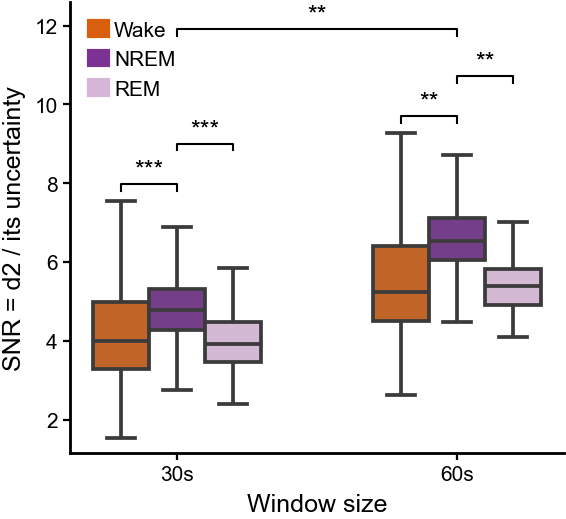

saved figure_output\supplementary\FigS2\FigS2_C_state_transition.svg / .png


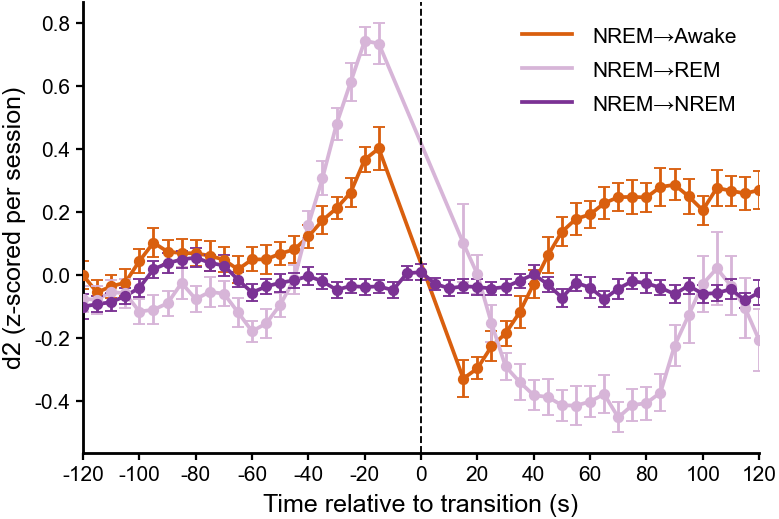

d: sleep vs wake, two-sided paired Wilcoxon signed-rank p = 0.0023; n = 18 sessions


saved figure_output\supplementary\FigS2\FigS2_D_wake_vs_sleep_d2.svg / .png


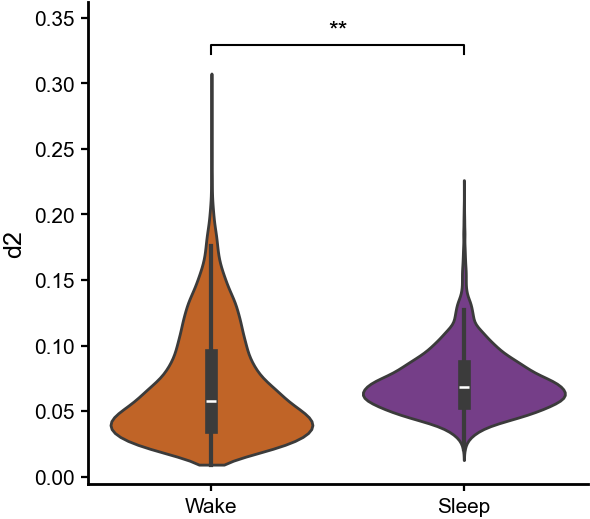

saved figure_output\supplementary\FigS2\FigS2_E_branching_ratio.svg / .png


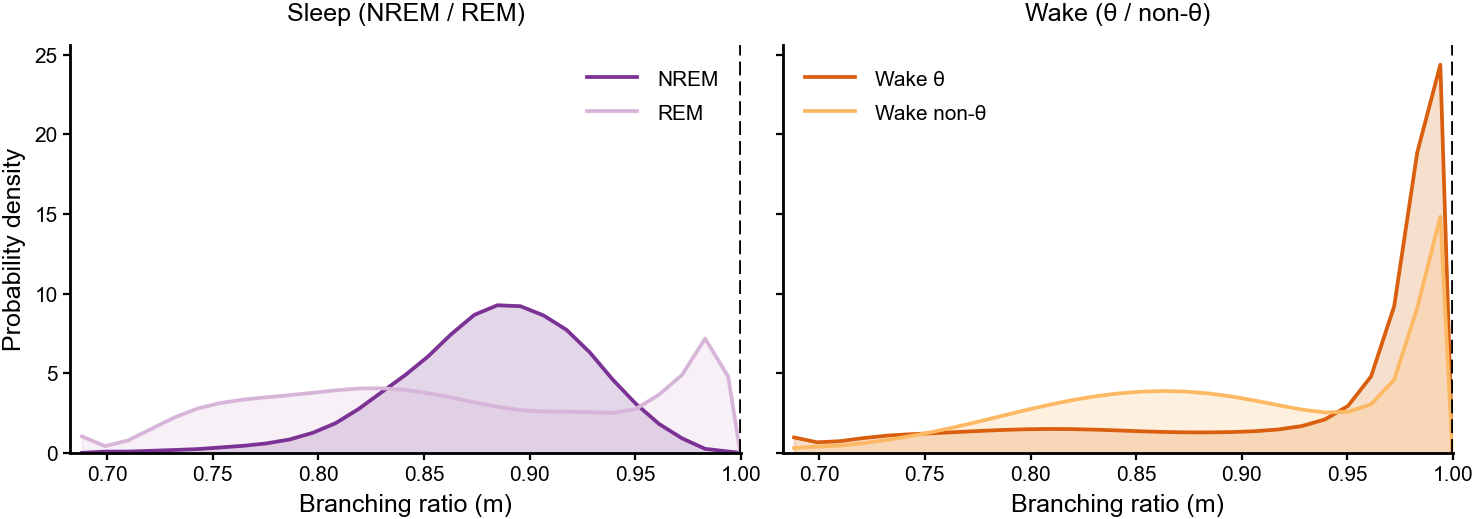

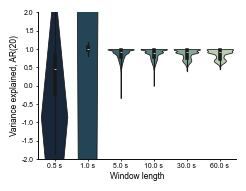

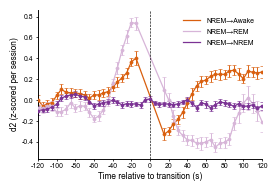

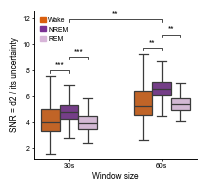

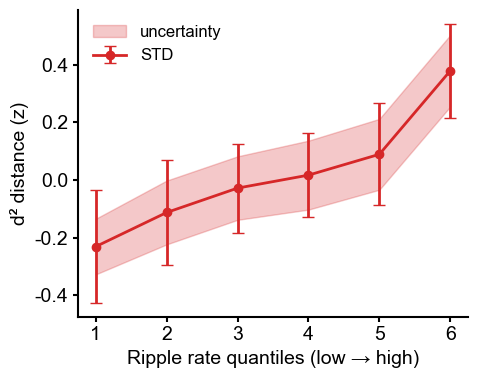

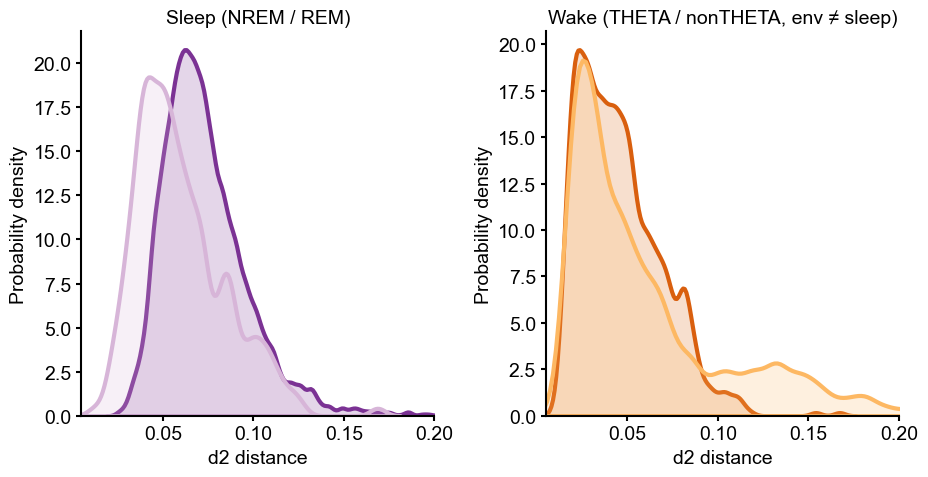

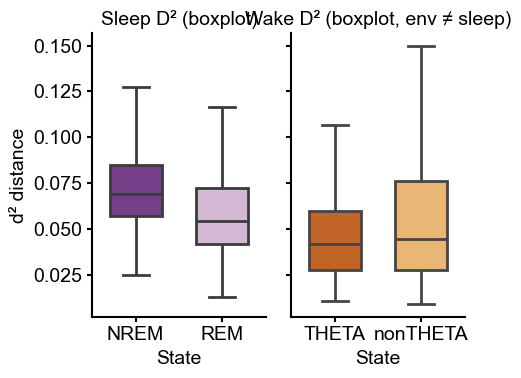

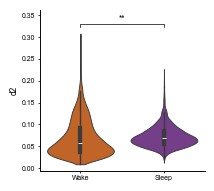

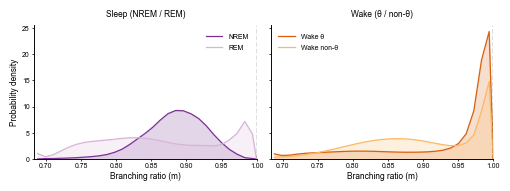

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# a-e: the submitted Extended Data Fig. 1 b-f notebooks (Previous_Rv1/sleep/figure_scripts), each run once as ed_nonoverlap
# runs them -- window tables thinned to disjoint windows, the rebuilt tables of ed_nonoverlap_tables/ (explained
# variance from the MATLAB centres, d2 uncertainty 30 / 60 s, branching ratio by state) -- with their figures captured
# instead of saved, then restyled to print size (F.restyle: 14 pt -> 6 pt, lines x 0.45). c is the
# transition panel on all windows.
CAP = {}
CAP.update(F.run_rv1_capture("FigS1_B_Explain variance_D_statetransition",
                             ["figS1B_explain_variance_violin_diff_window", "S1_D_nrem_d2_transition_snippets"]))
CAP.update(F.run_rv1_capture("FigS1_C_SNR_S2C_d2 uncertainty", ["S2_C_CA1_snr_box_30s_vs_60s"]))
SNR_LOG = F.LAST_RV1_LOG                               # its printed Holm-adjusted P values (b's stars)
CAP.update(F.run_rv1_capture("Fig1_D_histogram_S1_E", ["figS1_B_wake_sleep"]))
# e on every wake window, as d and f: the disjoint table without the producer's
# sleep-environment drop of θ / non-θ (ed_nonoverlap_ed2a_ed1f.py -> ed_nonoverlap_tables_allwake/)
CAP.update(F.run_rv1_capture("FigS1_F_branchingratio_histogram", ["S1_F_branching_ratio_distribution_split"],
                             override_dir=os.path.join(F.REPO, "data", "revision", "log", "ed_nonoverlap_tables_allwake")))


def save(fig, fig_id):
    F.settle(fig)
    F.drop_counts(fig)                                  # formal panel
    return F.save(fig, fig_id)


# ---- a: AR(20) variance explained by window length (0.5 and 1 s kept, explained in the legend: 12 and 25 bins of
#      40 ms against 20 coefficients)
fig = CAP["figS1B_explain_variance_violin_diff_window"]; ax = fig.axes[0]
ax.set_ylabel("Variance explained, AR(20)"); ax.set_xlabel("Window length")
ax.set_xticklabels([t.get_text().replace(" sec", " s") for t in ax.get_xticklabels()])
F.restyle(fig, 58, 44)
F.show(save(fig, "FigS2_A_explained_variance"))

# ---- b: SNR of d2, 30 s vs 60 s windows, by state
fig = CAP["S2_C_CA1_snr_box_30s_vs_60s"]; ax = fig.axes[0]
ax.set_ylabel("SNR = d2 / its uncertainty")
F.restyle(fig, 48, 44)
ax.legend(handles=[Patch(color=c, label=l) for c, l in (("#d95f0e", "Wake"), ("#7b3294", "NREM"), ("#d7b5d8", "REM"))],
          frameon=False, loc="upper left", fontsize=5, handlelength=0.9, handletextpad=0.3)   # the producer draws no legend
# brackets with the notebook's own session-paired Wilcoxon, Holm-adjusted, stars only:
# per window Wake-NREM and NREM-REM; across the top 30 vs 60 s (session mean over all states)
import re as _re
_log = open(SNR_LOG, encoding="utf-8").read()
_log = _log[_log.index("Multiple comparison correction"):]
PADJ = [float(v) for v in _re.findall(r"p_adj=([0-9.eE+-]+)", _log)][:5]    # 30 s A-N, 30 s N-R, 60 s A-N, 60 s N-R, 30 vs 60
assert len(PADJ) == 5, PADJ
print("b: two-sided paired Wilcoxon signed-rank, Holm-corrected: NREM vs Wake p = "
      f"{PADJ[0]:.3g} (30 s), {PADJ[2]:.3g} (60 s); NREM vs REM p = {PADJ[1]:.3g} (30 s), {PADJ[3]:.3g} (60 s); "
      f"60 s vs 30 s p = {PADJ[4]:.3g}")
lo, hi = ax.get_ylim(); span = hi - lo
tops = {}
for wc in (0, 1):                                      # whisker tops of each window group (boxes at -0.2, 0, +0.2)
    ys = [max(l.get_ydata()) for l in ax.lines if len(l.get_xdata()) and abs(float(np.mean(l.get_xdata())) - wc) < 0.35]
    tops[wc] = max(ys)
for wc, (p_an, p_nr) in ((0, PADJ[0:2]), (1, PADJ[2:4])):
    F.bracket(ax, wc - 0.2, wc, tops[wc] + 0.05 * span, F.stars(p_an), h=0.02 * span)
    F.bracket(ax, wc, wc + 0.2, tops[wc] + 0.17 * span, F.stars(p_nr), h=0.02 * span)
ytop = max(tops.values()) + 0.31 * span
F.bracket(ax, 0, 1, ytop, F.stars(PADJ[4]), h=0.02 * span)
ax.set_ylim(lo, ytop + 0.08 * span)
F.show(save(fig, "FigS2_B_snr_30_vs_60s"))

# ---- c: d2 around state transitions (submitted, all windows)
fig = CAP["S1_D_nrem_d2_transition_snippets"]; ax = fig.axes[0]
ax.set_ylabel("d2 (z-scored per session)")
F.restyle(fig, 66, 44)
F.show(save(fig, "FigS2_C_state_transition"))

# ---- d: d2, wake vs sleep (every wake window)
fig = CAP["figS1_B_wake_sleep"]; ax = fig.axes[0]
ax.set_ylabel("d2"); ax.set_xlabel("")
F.restyle(fig, 50, 44)
# bracket: session-paired signed-rank of session medians, sleep vs wake, on these disjoint windows
# (fig1de_nonoverlap_stats.csv, D_disjoint), stars only
_S = pd.read_csv(CSV / "fig1de_nonoverlap_stats.csv")   # fig1de_nonoverlap.py's statistics
sw = _S[(_S.panel == "1d") & (_S.arm == "D_disjoint") & (_S.contrast == "Sleep - Wake")].iloc[0]
print(f"d: sleep vs wake, two-sided paired Wilcoxon signed-rank p = {sw.p:.2g}; n = {int(sw.n_sessions)} sessions")
lo, hi = ax.get_ylim(); span = hi - lo
F.bracket(ax, 0, 1, hi + 0.02 * span, F.stars(sw.p), h=0.02 * span)
ax.set_ylim(lo, hi + 0.12 * span)
F.show(save(fig, "FigS2_D_wake_vs_sleep_d2"))

# ---- e: branching ratio distributions, sleep and wake states
fig = CAP["S1_F_branching_ratio_distribution_split"]
for ax_ in fig.axes:
    ax_.set_title(ax_.get_title().replace("THETA / nonTHETA", "θ / non-θ"))
F.restyle(fig, 125, 44)
F.show(save(fig, "FigS2_E_branching_ratio"))

## f: d2 vs MUA (disjoint) and the spontaneous firing-rate range (recomputed pairs, all windows)

f (left): d2 vs MUA (z within session), non-overlapping windows
  Wake non-θ: per-session Pearson r pooled by random-effects meta-analysis, r = -0.54, p = 2.2e-35
  Wake θ: per-session Pearson r pooled by random-effects meta-analysis, r = +0.17, p = 0.092
  NREM: per-session Pearson r pooled by random-effects meta-analysis, r = +0.23, p = 9.3e-09
  REM: per-session Pearson r pooled by random-effects meta-analysis, r = -0.16, p = 0.15


  NREM: per-session Spearman rho combined by Stouffer's method (one-sided), rho = -0.44, p = 0.00033
  REM: per-session Spearman rho combined by Stouffer's method (one-sided), rho = -0.51, p = 0.00019
  THETA: per-session Spearman rho combined by Stouffer's method (one-sided), rho = -0.78, p = 2.2e-10


  non-THETA: per-session Spearman rho combined by Stouffer's method (one-sided), rho = -0.84, p = 2.1e-17


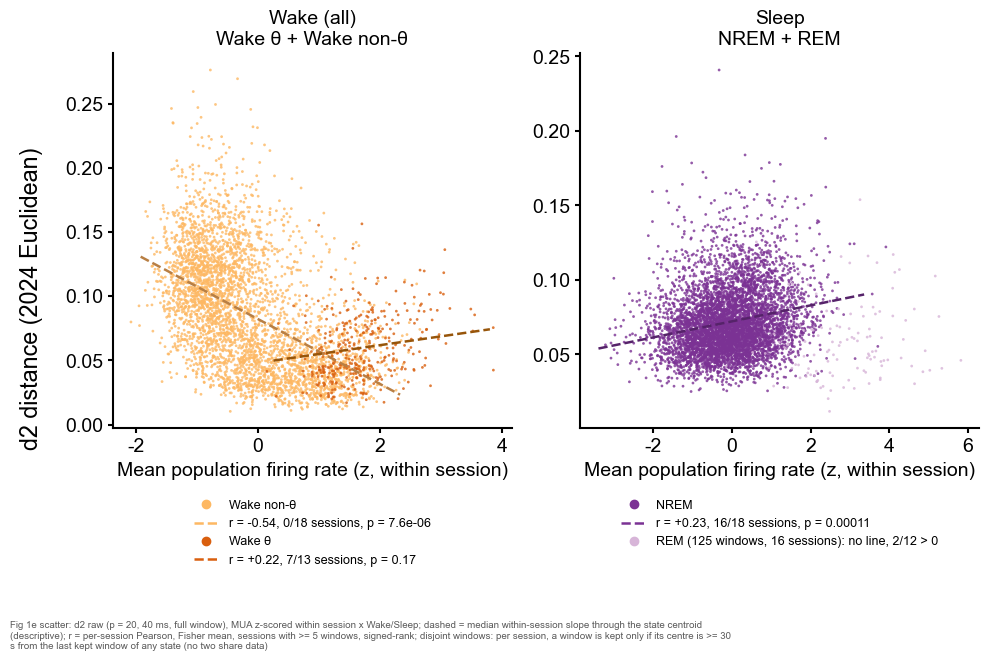

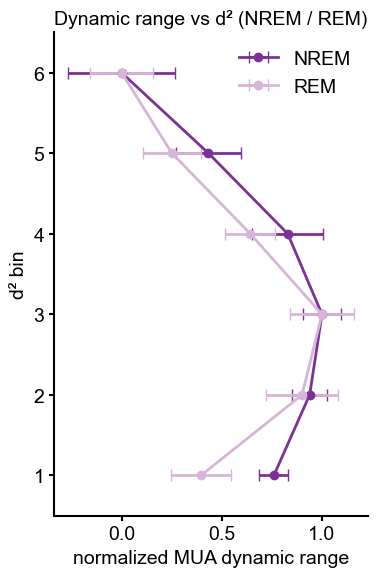

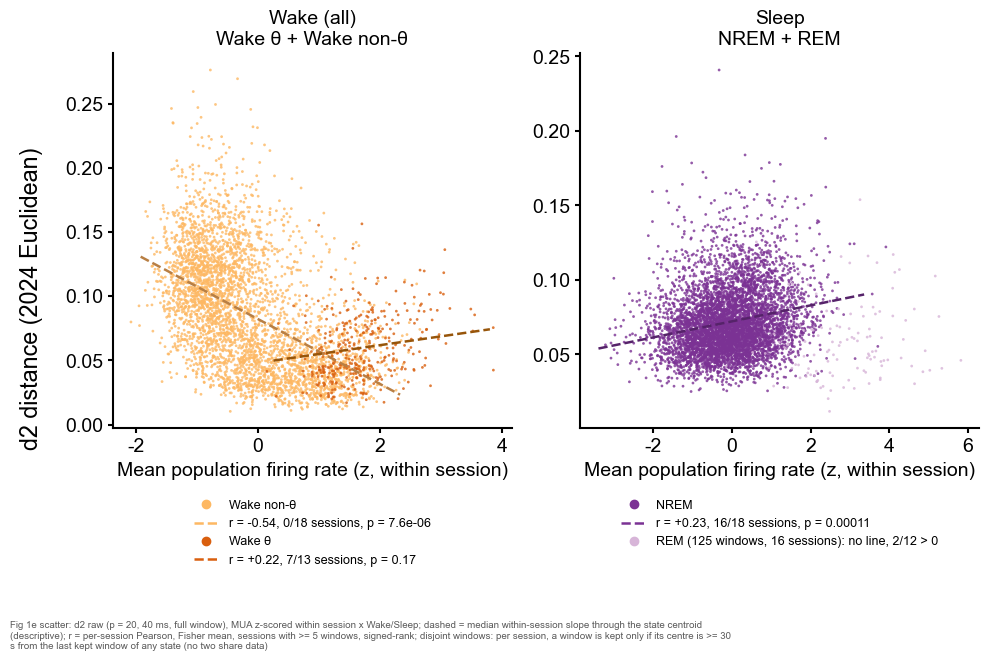

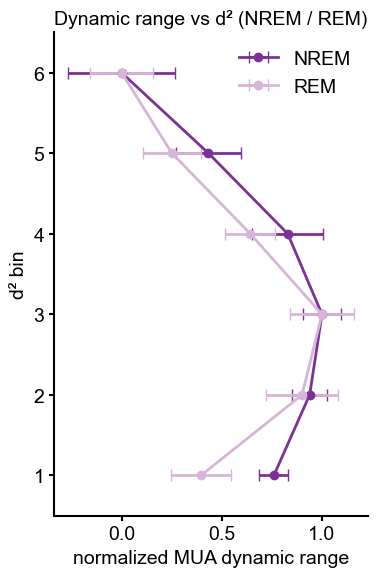

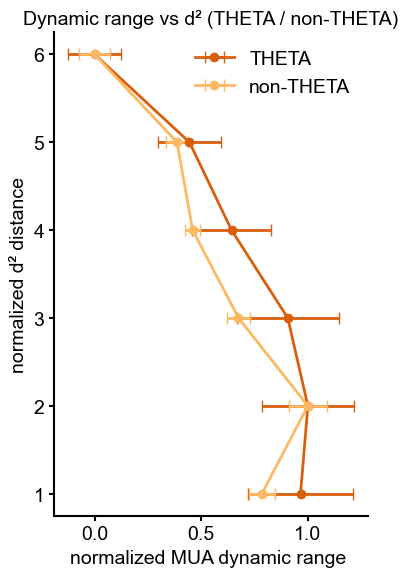

saved figure_output\supplementary\FigS2\FigS2_F_d2_vs_mua.svg / .png


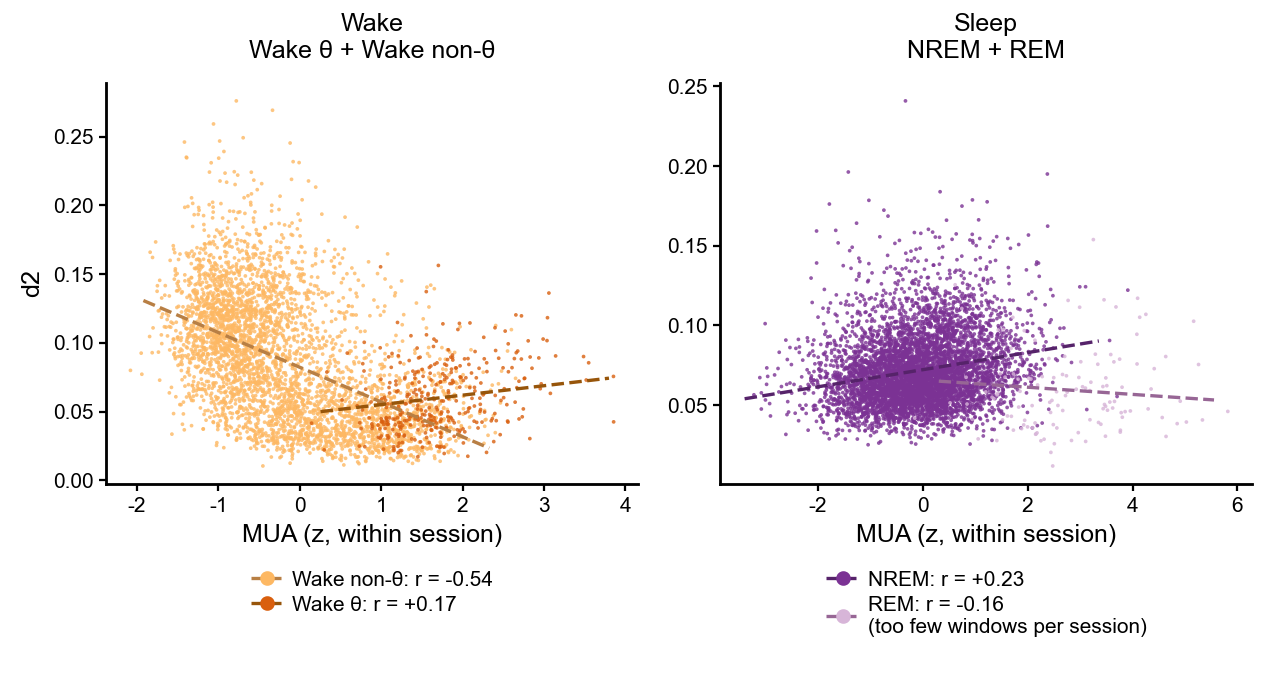

saved figure_output\supplementary\FigS2\FigS2_F_firing_rate_range_nrem_rem.svg / .png


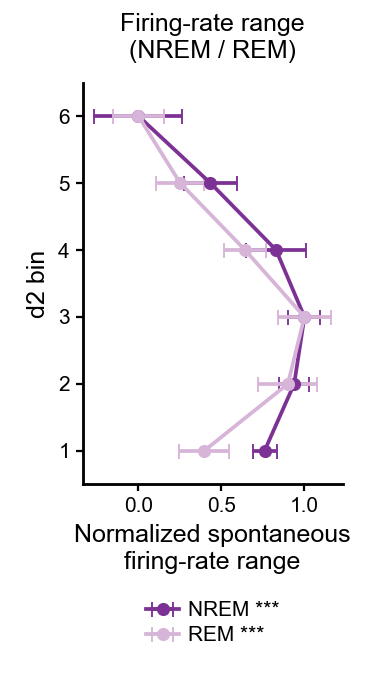

saved figure_output\supplementary\FigS2\FigS2_F_firing_rate_range_theta.svg / .png


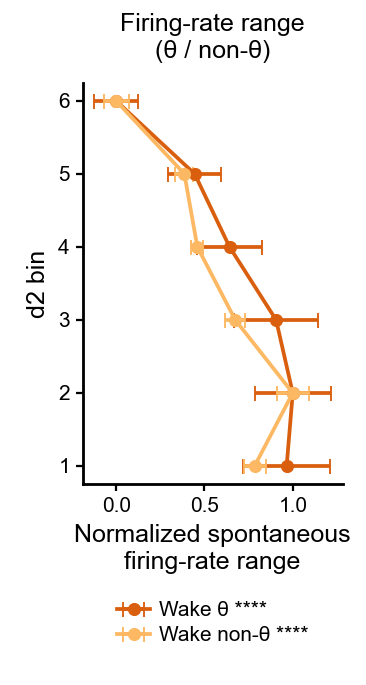

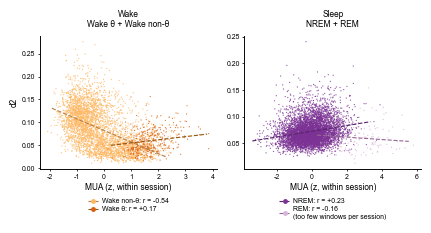

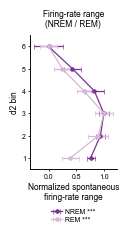

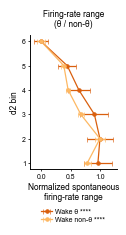

In [3]:
import tempfile
import pandas as pd
from matplotlib.lines import Line2D
import fig1e_scatter_d2raw_drawing as SC   # fig1e_scatter_d2raw.py's figure code (copied)
import types
D1 = types.SimpleNamespace(LOGDIR=str(CSV))   # (fig1de_nonoverlap.py: only the folder of its tables is used here)

# f combines the d2-MUA scatter and the MUA dynamic range in one panel, in the same order. Both on the recomputed
# pairs (data/revision/log/fig1e_pairs_recomputed.csv: each session's own d2 from its _error_bar.mat -- PPP7_day14
# with its own d2, PPP7_day7 with every theta bout).
# Scatter: fig1e_scatter_d2raw.main (d2 raw, MUA z within session x Wake/Sleep, disjoint windows) with WAKE = all --
# every wake window, home cage included, as the dynamic range uses; its CSV / figure writes redirected to a temp
# folder. Dynamic range: the Fig1_E_..._dynrange.ipynb's dynamic-range cell, on all windows of the recomputed pairs,
# REM included, overlapping windows.
tmp = tempfile.mkdtemp(prefix="figs2_f_")
_alp, _wake = SC.assert_local_path, SC.WAKE
SC.assert_local_path = lambda p: os.path.join(tmp, os.path.basename(p))      # the producer's own outputs untouched
SC.WAKE = "all"
try:
    # ---- data (../csv) ----
    # fig1e_scatter_d2raw.main(): the recomputed pairs, disjoint windows, task epochs tagged, MUA z per session x Wake/Sleep;
    # drawn (and its statistics computed) by its own figure code
    CAPF = F.capture_figures(lambda: SC.draw_main(read_csv("figs2f_scatter_windows.csv")), ["fig1e_scatter_d2raw_muaz_nonoverlap"])
    # ---- the same from the recordings, with analysis_scripts/: ----
    # CAPF = F.capture_figures(SC.main, ["fig1e_scatter_d2raw_muaz_nonoverlap"])
finally:
    SC.assert_local_path, SC.WAKE = _alp, _wake
SCS = pd.read_csv(os.path.join(tmp, "fig1e_scatter_d2raw_stats_allwake.csv")).set_index("state")   # this run's statistics
import glob as _glob, re as _re
from scipy import stats as _stats
Rp = pd.read_csv(os.path.join(D1.LOGDIR, "fig1e_pairs_recomputed.csv"))
ns = {"__name__": "figs2_dynrange", "np": np, "pd": pd, "plt": plt, "stats": _stats, "os": os, "re": _re, "glob": _glob}
exec(open("fig1e_dynrange_cell1.py", encoding="utf-8").read(), ns)   # the Fig 1e notebook's functions
ns["all_pairs"] = Rp                                                        # recomputed pairs, every window
CAPF.update(F.capture_figures(lambda: exec(open("fig1e_dynrange_cell2.py", encoding="utf-8").read(), ns),
                              ["fig1_E_NREM_vs_REM_dyn_by_d2", "fig1_E_THETA_vs_nonTHETA_dyn_by_d2"]))
# the dynamic range's statistic: per-file Spearman(d2 bin, dynamic range), Stouffer, one-sided (the published test),
# on these recomputed pairs, all windows (fig1de_nonoverlap_stats.csv, arm B_corrected_all)
_S = pd.read_csv(os.path.join(D1.LOGDIR, "fig1de_nonoverlap_stats.csv"))
DYN = _S[(_S.panel == "1e") & (_S.arm == "B_corrected_all")].set_index("contrast")

# All three f figures share one axes geometry, so the dynamic range's y axis is as long as the scatter's: figure
# height H, axes from B to H - T mm, legends below the axes; saved untight so the sizes hold.
H, B, T = 58.0, 17.0, 7.0                              # mm: room below for 2-line x labels + legend
AX_H = H - B - T


def place(fig, w_mm, lefts, width):
    fig.set_layout_engine("none")
    fig.set_size_inches(w_mm * F.MM, H * F.MM)
    for ax_, l in zip(fig.axes, lefts):
        ax_.set_position([l / w_mm, B / H, width / w_mm, AX_H / H])


def legend_below(ax_, handles, labels, gap_mm=6.6):
    ax_.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -gap_mm / AX_H), frameon=False, fontsize=5,
               handlelength=1.6, handletextpad=0.4, borderaxespad=0, labelspacing=0.3)


# ---- f (left): d2 raw vs MUA z -- REM drawn too (its median within-session slope), legend: state + weighted r
fig = CAPF["fig1e_scatter_d2raw_muaz_nonoverlap"]
if fig._supylabel is not None:
    fig._supylabel.set_visible(False)
F.restyle(fig, 108, H, drop_texts=("Fig 1e scatter",))
axw, axs = fig.axes
for ax_ in fig.axes:
    ax_.set_xlabel("MUA (z, within session)")
    ax_.title.set_fontsize(6)                          # as the dynamic-range titles
    if ax_.get_legend():
        ax_.get_legend().remove()
axw.set_ylabel("d2")
axw.set_title("Wake\nWake θ + Wake non-θ", fontsize=6)   # all wake, not labelled "(all)"
rem = axs.collections[1].get_offsets()                                     # the REM points (NREM drawn first)
x0, x1 = SC.local_limits(pd.Series(rem[:, 0]), 0.05)
xs = np.linspace(x0, x1, 50)
cx, cy = rem[:, 0].mean(), rem[:, 1].mean()
axs.plot(xs, cy + SCS.loc["REM", "slope_per_sd_median"] * (xs - cx), color=SC.SLEEP_LINE["REM"], ls="--", lw=0.8)


def entry(st, pal, lpal):
    """legend entry: the state and its pooled per-session Pearson r, each session weighted by its window count
    (random-effects meta-analysis of the per-session Fisher z, fig1e_scatter_d2raw.meta_r, since sessions with
    few windows fit poorly). No stars on the figure: its p goes in the written figure legend."""
    s_ = SCS.loc[st]
    h = Line2D([0], [0], marker="o", ms=2.5, ls="--", lw=0.8, color=lpal[st], markerfacecolor=pal[st], markeredgecolor=pal[st])
    if st == "REM":                                       # few windows per session
        return h, f"REM: r = {s_.r_re:+.2f}\n(too few windows per session)"
    return h, f"{st}: r = {s_.r_re:+.2f}"


GROUPS = ((axw, ("Wake non-θ", "Wake θ"), SC.WAKE_PAL, SC.WAKE_LINE), (axs, ("NREM", "REM"), SC.SLEEP_PAL, SC.SLEEP_LINE))
place(fig, 108, (9.0, 61.0), 45.0)                       # wider: the dynamic range is narrower
for ax_, sts, pal, lpal in GROUPS:
    hl = [entry(st, pal, lpal) for st in sts]
    legend_below(ax_, [h for h, _ in hl], [l for _, l in hl])
F.show(F.save(fig, "FigS2_F_d2_vs_mua", tight=False))

# ---- f (right): spontaneous firing-rate range by d2 bin, recomputed pairs, all windows -- legend: state + stars.
# The submitted "dynamic range", renamed here to avoid confusion with Kinouchi-Copelli's stimulus-response
# dynamic range: per session and d2 bin, 10 log10(p95 / p05) of the 30 s windows' MUA (each window's rate over the
# bin mean), averaged over sessions and min-max scaled 0-1 within each state.
NAME = {"THETA": "Wake θ", "non-THETA": "Wake non-θ"}
for key, fid, title in (("fig1_E_NREM_vs_REM_dyn_by_d2", "FigS2_F_firing_rate_range_nrem_rem", "Firing-rate range\n(NREM / REM)"),
                        ("fig1_E_THETA_vs_nonTHETA_dyn_by_d2", "FigS2_F_firing_rate_range_theta", "Firing-rate range\n(θ / non-θ)")):
    fig = CAPF[key]
    F.restyle(fig, 31, H)                              # narrower
    ax_ = fig.axes[0]
    ax_.set_title(title, fontsize=6)                    # set after restyle: give the print size explicitly
    ax_.set_ylabel("d2 bin")
    ax_.set_xlabel("Normalized spontaneous\nfiring-rate range")
    h, lab = ax_.get_legend_handles_labels()
    lab2 = []
    for l in lab:
        r_ = DYN.loc[l]
        lab2.append(f"{NAME.get(l, l)} {F.stars(r_.p)}")
    if ax_.get_legend():
        ax_.get_legend().remove()
    legend_below(ax_, h, lab2, gap_mm=9.2)              # below the 2-line x label
    place(fig, 31, (7.0,), 22.0)
    F.settle(fig, tight=False)
    F.drop_counts(fig)
    F.show(F.save(fig, fid, tight=False))

## g, h: AR order and residual whiteness; d2 by state, full window and ripple-excised

- **g** Fraction of windows with white AR(p) residuals (Ljung–Box, 50 lags, df = 50 − p, p > 0.05) by AR order and state; 18 sessions, 12 345 non-overlapping 30 s windows. Drawing `letter_figs_r12_r13.r12`; data `ljungbox_df_audit.csv`.
- **h** d2 by state, full window (grey) and ripple-excised (red): per-session medians, mean ± SEM over 16 sessions (14 with REM); non-overlapping 30 s windows, wake split by the window centre. Stars: NREM vs REM and Wake non-θ vs Wake θ, two-sided paired Wilcoxon signed-rank of the session medians. Drawing: panel a of `d2_arms_raw.main`; data `d2_arms_raw_windows_centre.csv`.

whiteness (df-corrected), %: 18 sessions, 12345 windows ({'NREM': 6042, 'REM': 227, 'THETA': 231, 'nonTHETA': 5845})
order       5     10    15    20    30    40
state                                       
NREM      79.5  85.9  89.9  91.6  91.1  84.9
REM       65.2  89.4  92.1  93.4  95.2  87.2
THETA     78.4  85.3  91.8  93.5  93.5  90.0
nonTHETA  71.7  86.5  91.3  92.7  91.5  84.2
  -> .\r12_order_selection.png


saved figure_output\supplementary\FigS2\FigS2_G_ar_order_whiteness.svg / .png


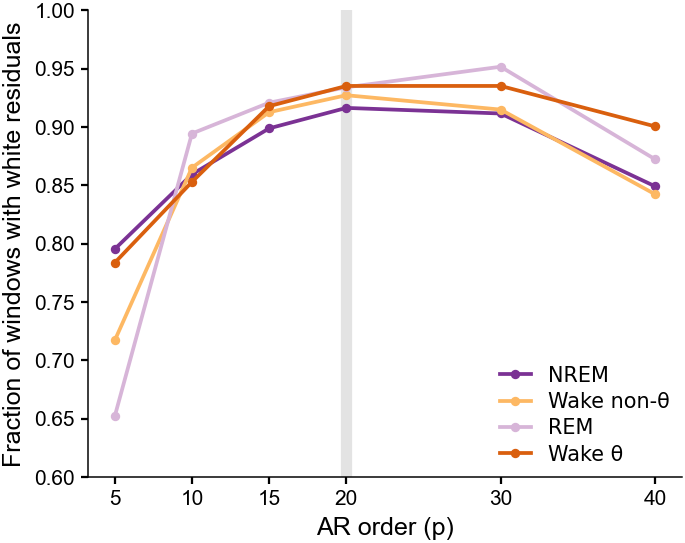


STATES -- per-session median d2 (2024 Euclidean, p = 20), mean +- SEM over sessions; paired vs NREM
  state              n |     full      +- |  excised      +- | vs NREM full (n<NREM /n, p) | excised
  NREM              16 |   0.0696  0.0024 |   0.0737  0.0024 |
  REM               14 |   0.0568  0.0043 |   0.0572  0.0046 | 12/14 p=0.0040 | 11/14 p=0.0052 |
  theta wake        16 |   0.0500  0.0022 |   0.0482  0.0020 | 16/16 p=0.0000 | 16/16 p=0.0000 |
  non-theta wake    16 |   0.0679  0.0056 |   0.0595  0.0043 | 10/16 p=0.5966 | 14/16 p=0.0017 |
  within-pair contrasts (paired, per-session medians):
    NREM - REM       d2_full     median diff +0.0169  12/14 NREM higher  p = 0.0040
    NREM - REM       d2_excised  median diff +0.0220  11/14 NREM higher  p = 0.0052
    nonTHETA - THETA     d2_full     median diff +0.0159  13/16 nonTHETA higher  p = 0.0017
    nonTHETA - THETA     d2_excised  median diff +0.0084  13/16 nonTHETA higher  p = 0.0052


  -> .\d2_arms_raw.png


saved figure_output\supplementary\FigS2\FigS2_H_d2_by_state_both_arms.svg / .png


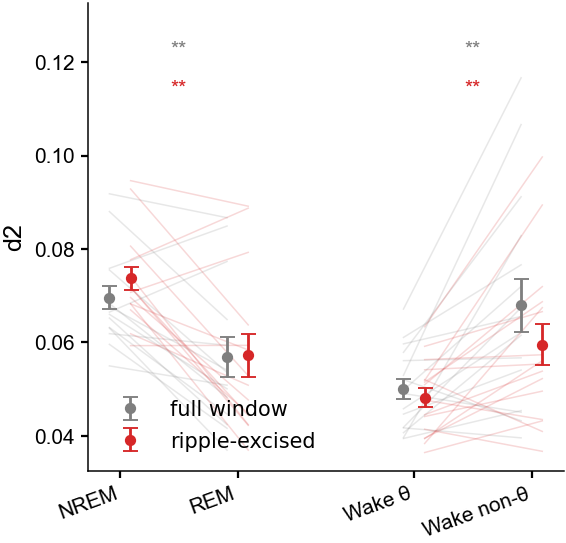

'centre'

In [4]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import si_panels as SP                     # no_csv, producer

mpl.rcdefaults()                           # g, h start from matplotlib's defaults (the code above changes them)
plt.rcParams.update({"svg.fonttype": "none", "pdf.fonttype": 42})   # text stays text, as in the other panels


def width_mm(fig_id):
    """a saved panel's width in mm: the width attribute of its root <svg> element"""
    import re
    s = open(F.stem(fig_id) + ".svg", encoding="utf-8").read()
    v, unit = re.search(r'<svg\b[^>]*?\swidth="([0-9.]+)\s*([a-z]*)"', s).groups()
    return float(v) * {"mm": 1.0, "pt": 25.4 / 72, "px": 25.4 / 96, "in": 25.4, "": 25.4 / 96, "cm": 10.0}[unit]


W_A = width_mm("FigS2_A_explained_variance")    # g as wide as a, h as wide as b (saved above)
W_B = width_mm("FigS2_B_snr_30_vs_60s")
H_GH = 46.0
WAKE = {"theta wake": "Wake θ", "non-theta wake": "Wake non-θ"}           # the state names of e, f


def ed2_text(ax):
    """the text sizes of the other panels: tick labels 5 pt, axis labels 6 pt, legend and in-panel text 5 pt"""
    ax.tick_params(labelsize=5)
    ax.xaxis.label.set_size(6); ax.yaxis.label.set_size(6)
    for t in ax.texts + (ax.get_legend().get_texts() if ax.get_legend() else []):
        t.set_fontsize(5)

# g: AR order vs residual whiteness, by state
with plt.rc_context(), SP.no_csv():
    # ---- data (../csv) ----
    M = SP.producer("letter_figs_r12_r13_drawing")      # letter_figs_r12_r13.py's figure code (copied)
    LB = read_csv("ljungbox_df_audit.csv")             # ljungbox_df_audit.py: Ljung-Box p per window and AR order
    fig = F.capture_figures(lambda: M.draw_r12(LB), ["r12_order_selection"])["r12_order_selection"]
    # ---- the same from the recordings, with analysis_scripts/: ----
    # M = SP.producer("letter_figs_r12_r13")
    # fig = F.capture_figures(M.r12, ["r12_order_selection"])["r12_order_selection"]
ax = fig.axes[0]
ax.set_xlabel("AR order (p)")                                              # 40 ms bins: in the legend
for ln in ax.get_lines():                                                  # restyle rebuilds the legend from these
    ln.set_label(WAKE.get(ln.get_label(), ln.get_label()))
F.restyle(fig, W_A, H_GH, font=6 / 9)
ax.legend(frameon=False, loc="lower right", fontsize=5, handlelength=1.5, labelspacing=0.3, borderaxespad=0.2)
ed2_text(ax)
F.show(F.save(fig, "FigS2_G_ar_order_whiteness"))
plt.close(fig)

# h: d2 by state, both arms
with plt.rc_context(), SP.no_csv():
    M = SP.producer("d2_arms_raw_drawing", {"LABEL": "centre"})   # d2_arms_raw.py's figure code (copied)
    M.stars = F.stars
    # ---- data (../csv) ----
    Fs = read_csv("d2_arms_raw_windows_centre.csv")    # d2_arms_raw.py: both arms per window, wake split by centre
    fig = F.capture_figures(lambda: M.draw_main(Fs), ["d2_arms_raw"])["d2_arms_raw"]
    # ---- the same from the recordings, with analysis_scripts/: ----
    # M = SP.producer("d2_arms_raw", {"FIG1_ONLY": "1", "LABEL": "centre"})
    # M.stars = F.stars
    # fig = F.capture_figures(M.main, ["d2_arms_raw"])["d2_arms_raw"]
for a in fig.axes[1:]:                                                     # only panel a of the producer's figure
    fig.delaxes(a)
for t in list(fig.texts):                                                  # the suptitle belongs in the legend
    t.remove()
fig._suptitle = None
ax = fig.axes[0]
ax.set_subplotspec(GridSpec(1, 1, figure=fig)[0])                         # the whole figure, not a quarter of it
ax.set_title("", loc="left")                                               # "a  states ..., 16 sessions": legend
ax.set_ylabel("d2")
ax.set_xticklabels([WAKE.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()], rotation=20, ha="right")
F.restyle(fig, W_B, H_GH, font=6 / 9)
ed2_text(ax)
F.settle(fig)
F.drop_counts(fig)                                                         # formal panel: the stars only
F.show(F.save(fig, "FigS2_H_d2_by_state_both_arms"))
plt.close(fig)
os.environ.pop("LABEL", None)